In [ ]:
%pip install -q ultralytics==8.4.1 pycocotools==2.0.11
!git clone https://github.com/mdmohsin212/WasteScope.git

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 4.3 MB/s eta 0:00:00a 0:00:01
Cloning into 'WasteScope'...
remote: Enumerating objects: 363, done.
remote: Counting objects: 100% (363/363), done.
remote: Compressing objects: 100% (198/198), done.
remote: Total 363 (delta 186), reused 302 (delta 131), pack-reused 0 (from 0)
Receiving objects: 100% (363/363), 15.28 MiB | 19.64 MiB/s, done.
Resolving deltas: 100% (186/186), done.


In [2]:
import sys
from pathlib import Path

from google.colab import drive
drive.mount("/content/drive")

REPO_DIR = Path("/content/WasteScope")
sys.path.insert(0, str(REPO_DIR))

Mounted at /content/drive


In [4]:
import hashlib
import json
import platform
import shutil
import sys
import time
import cv2
import torch
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path
from zipfile import ZipFile
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import ultralytics
from IPython.display import display
from pycocotools import mask as mask_utils
from pycocotools.coco import COCO
from tqdm.auto import tqdm
from ultralytics import YOLO
from src.evaluation.metrics import coco_results, detection_errors, evaluate_coco


PROJECT_DIR = Path("/content/drive/MyDrive/WasteScope")

RUN_NAME = "S0_yolo26n_seg_640"
CHECKPOINT = "best.pt"
SPLIT = "val"

IMGSZ = None
DEVICE = 0
HALF = True

AP_CONF = 0.001
CONF = 0.25
MATCH_IOU = 0.50
MAX_DET = 100
BOUNDARY_RATIO = 0.02
WARMUP = 10

ROOT = Path("/content/wastescope")
DATA = ROOT / "segmentation_prepared"
ROOT.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_DIR)
print("GPU:", torch.cuda.get_device_name(DEVICE))
print("Ultralytics:", ultralytics.__version__)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Project: /content/drive/MyDrive/WasteScope
GPU: Tesla T4
Ultralytics: 8.4.1


In [5]:
ANNOTATIONS = DATA / SPLIT / "annotations.json"

if not ANNOTATIONS.is_file():
    archive_path = ROOT / "segmentation_zips" / f"{SPLIT}.zip"
    archive_path.parent.mkdir(parents=True, exist_ok=True)

    if not archive_path.is_file():
        print(f"Copying {SPLIT}.zip from Drive")
        shutil.copy2(
            PROJECT_DIR / "prepared" / "segmentation" / f"{SPLIT}.zip", archive_path
        )

    DATA.mkdir(parents=True, exist_ok=True)
    with ZipFile(archive_path) as archive:
        for member in tqdm(
            archive.infolist(), desc=f"Extracting {SPLIT}"
        ):
            archive.extract(member, DATA)

SOURCE_WEIGHTS = (
    PROJECT_DIR / "runs" / "segment"
    / RUN_NAME / "weights" / CHECKPOINT
)
WEIGHTS = ROOT / "analysis_weights" / RUN_NAME / CHECKPOINT
WEIGHTS.parent.mkdir(parents=True, exist_ok=True)
shutil.copy2(SOURCE_WEIGHTS, WEIGHTS)

Copying val.zip from Drive


Extracting val:   0%|          | 0/2061 [00:00<?, ?it/s]

PosixPath('/content/wastescope/analysis_weights/S0_yolo26n_seg_640/best.pt')

In [6]:
model = YOLO(str(WEIGHTS))
IMGSZ = int(IMGSZ or model.overrides.get("imgsz", 640))

coco = COCO(str(ANNOTATIONS))
CATEGORY_ID = coco.getCatIds(catNms=["Overflow"])[0]
images = coco.loadImgs(sorted(coco.getImgIds()))

REPORT_TAG = f"{SPLIT}_{Path(CHECKPOINT).stem}_{IMGSZ}_conf{CONF:g}"

REPORT = (
    PROJECT_DIR / "reports" / "segmentation"
    / RUN_NAME / REPORT_TAG
)
REPORT.mkdir(parents=True, exist_ok=True)

print("Run:", RUN_NAME)
print("Split:", SPLIT)
print("Images:", len(images))
print("Image size:", IMGSZ)
print("Reports:", REPORT)

loading annotations into memory...
Done (t=0.03s)
creating index...
index created!
Run: S0_yolo26n_seg_640
Split: val
Images: 1030
Image size: 640
Reports: /content/drive/MyDrive/WasteScope/reports/segmentation/S0_yolo26n_seg_640/val_best_640_conf0.25


**Mask helpers**

In [7]:
def infer(image):
    result = model.predict(
        image,
        imgsz=IMGSZ,
        conf=AP_CONF,
        device=DEVICE,
        half=HALF,
        batch=1,
        rect=False,
        retina_masks=True,
        classes=[0],
        max_det=MAX_DET,
        save=False,
        verbose=False
    )[0]
    
    if result.masks is None:
        height, width = image.shape[:2]
        return (
            np.zeros((0, height, width), dtype=bool),
            np.empty(0, dtype=np.float32)
        )
    
    return (
        result.masks.data.cpu().numpy().astype(bool),
        result.boxes.conf.cpu().numpy()
    )


def ground_truth_rles(image_id):
    return [
        coco.annToRLE(annotation)
        for annotation in coco.imgToAnns[image_id]
        if annotation["category_id"] == CATEGORY_ID
    ]

def union_mask(rles, height, width):
    if not rles:
        return np.zeros((height, width), dtype=bool)
    return mask_utils.decode(mask_utils.merge(rles)).astype(bool)

In [8]:
def boundary(mask):
    thickness = max(1, round(BOUNDARY_RATIO * np.hypot(*mask.shape)))
    
    padded = cv2.copyMakeBorder(
        mask.astype(np.uint8),
        1, 1, 1, 1,
        cv2.BORDER_CONSTANT, value=0
    )
    
    eroded = cv2.erode(
        padded,
        np.ones((3, 3), dtype=np.uint8),
        iterations=thickness
    )[1:-1, 1:-1]
    
    return mask.astype(bool) & ~eroded.astype(bool)


def divide(numerator, denominator):
    return float(numerator / denominator) if denominator else None

**Generate predictions and foreground measurements**

In [ ]:
first_image = cv2.imread(
    str(DATA / SPLIT / "images" / Path(images[0]["file_name"]).name)
)

for _ in range(WARMUP):
    infer(first_image)

In [ ]:
torch.cuda.synchronize(DEVICE)
predictions = []
operating_predictions = {}
pixel_rows = []

for info in tqdm(images, desc=f"Analysing {SPLIT}"):
    image_id = info["id"]
    filename = Path(info["file_name"]).name

    image = cv2.imread(str(DATA / SPLIT / "images" / filename))
    height, width = image.shape[:2]

    torch.cuda.synchronize(DEVICE)
    started = time.perf_counter()
    masks, scores = infer(image)
    torch.cuda.synchronize(DEVICE)
    latency_ms = (time.perf_counter() - started) * 1000

    all_rles = [
        mask_utils.encode(
            np.asfortranarray(mask, dtype=np.uint8)
        ) for mask in masks
    ]

    for rle, score in zip(all_rles, scores):
        predictions.append({
            "image_id": image_id,
            "category_id": CATEGORY_ID,
            "segmentation": {
                "size": rle["size"],
                "counts": rle["counts"].decode("ascii"),
            },
            "score": float(score)
        })

    selected = np.flatnonzero(scores > CONF)
    pred_rles = [all_rles[index] for index in selected]
    operating_predictions[image_id] = pred_rles

    gt_union = union_mask(
        ground_truth_rles(image_id),
        height, width
    )
    
    pred_union = masks[selected].any(axis=0)
    intersection = int((gt_union & pred_union).sum())
    gt_pixels = int(gt_union.sum())
    pred_pixels = int(pred_union.sum())
    fp_pixels = int((pred_union & ~gt_union).sum())

    pixel_rows.append({
        "Image ID": image_id,
        "IntersectionPixels": intersection,
        "GTPixels": gt_pixels,
        "PredPixels": pred_pixels,
        "FPPixels": fp_pixels,
        "FPAreaPct": 100 * fp_pixels / (height * width),
        "IoU": divide(
            intersection,
            gt_pixels + pred_pixels - intersection
        ),
        "Dice": divide(
            2 * intersection,  gt_pixels + pred_pixels,
        ),
        "LatencyMs": latency_ms
    })

pixel_table = pd.DataFrame(pixel_rows).set_index("Image ID")
(REPORT / "predictions.json").write_text(
    json.dumps(predictions), encoding="utf-8"
)

Analysing val:   0%|          | 0/1030 [00:00<?, ?it/s]

193256

**COCO evaluation and error matching**

In [11]:
evaluator = evaluate_coco(
    coco.dataset,
    predictions,
    iou_type="segm"
)

coco_table = coco_results(evaluator)
errors = detection_errors(
    evaluator, confidence=CONF, iou=MATCH_IOU
)
per_image = errors.per_image.join(pixel_table)

threshold_index = int(
    np.flatnonzero(
        np.isclose(evaluator.params.iouThrs, MATCH_IOU)
    )[0]
)
all_area = evaluator.params.areaRng[
    evaluator.params.areaRngLbl.index("all")
]

boundary_rows = []
for item in evaluator.evalImgs:
    if item is None or item["aRng"] != all_area:
        continue
    
    for pred_id, gt_id in zip(
        item["dtIds"],
        item["dtMatches"][threshold_index]
    ):
        if pred_id not in errors.reviewed_prediction_ids or gt_id == 0:
            continue
        
        gt_id = int(gt_id)
        gt_mask = evaluator.cocoGt.annToMask(
            evaluator.cocoGt.anns[gt_id]
        )
        pred_mask = evaluator.cocoDt.annToMask(
            evaluator.cocoDt.anns[pred_id]
        )
        
        gt_boundary = boundary(gt_mask)
        pred_boundary = boundary(pred_mask)
        
        boundary_rows.append({
            "Image ID": item["image_id"],
            "Prediction ID": pred_id,
            "GT ID": gt_id,
            "BoundaryIoU": float(
                (gt_boundary & pred_boundary).sum()
                / (gt_boundary | pred_boundary).sum()
            )
        })

creating index...
index created!
Loading and preparing results...
DONE (t=0.01s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=0.21s).
Accumulating evaluation results...
DONE (t=0.04s).


In [12]:
boundary_matches = pd.DataFrame(
    boundary_rows,
    columns=["Image ID", "Prediction ID", "GT ID", "BoundaryIoU"]
)

intersection = int(per_image["IntersectionPixels"].sum())
gt_pixels = int(per_image["GTPixels"].sum())
pred_pixels = int(per_image["PredPixels"].sum())

foreground_iou = divide(
    intersection,
    gt_pixels + pred_pixels - intersection
)

dice = divide(2 * intersection, gt_pixels + pred_pixels)
gt_instances = int(per_image["Objects"].sum())
matched_instances = len(errors.matched_gt_ids)
missed_instances = len(errors.missed_gt_ids)

negative_images = per_image[per_image["Objects"] == 0]
latencies = per_image["LatencyMs"].to_numpy()

In [13]:
metrics = {
    "mask_mAP50_95": float(
        coco_table.loc["All Classes", "AP@[.50:.95]"]
    ),
    "mask_AP50": float(
        coco_table.loc["All Classes", "AP@0.50"]
    ),
    "boundary_IoU_matched": (
        float(boundary_matches["BoundaryIoU"].mean())
        if len(boundary_matches) else None
    ),
    "overall_foreground_IoU": foreground_iou,
    "Dice": dice,
    "false_positive_mask_area_pct": float(
        per_image["FPAreaPct"].mean()
    ),
    "negative_false_positive_mask_area_pct": (
        float(negative_images["FPAreaPct"].mean())
        if len(negative_images) else None
    ),
    "missed_overflow_rate_pct": divide(
        100 * missed_instances, gt_instances
    ),
    "gt_instances": gt_instances,
    "matched_instances": matched_instances,
    "missed_instances": missed_instances,
    "false_positive_instances": len(errors.false_positive_ids),
    "latency_mean_ms": float(np.mean(latencies)),
    "latency_P50_ms": float(np.percentile(latencies, 50)),
    "latency_P95_ms": float(np.percentile(latencies, 95))
}

per_class = (
    coco_table.drop(index="All Classes").join(errors.per_class)
)

per_class.loc["Overflow", "IoU"] = foreground_iou
per_class.loc["Overflow", "Dice"] = dice
metrics_table = pd.DataFrame(
    list(metrics.items()),
    columns=["metric", "value"]
)

per_image.to_csv(REPORT / "per_image.csv")
per_class.to_csv(REPORT / "per_class.csv")
boundary_matches.to_csv(REPORT / "boundary_matches.csv", index=False)
metrics_table.to_csv(REPORT / "metrics.csv", index=False)

display(metrics_table.round(4))
display(per_class.round(4))

,metric,value
0,mask_mAP50_95,0.1478
1,mask_AP50,0.2660
2,boundary_IoU_matched,0.7764
3,overall_foreground_IoU,0.2638
4,Dice,0.4175
5,false_positive_mask_area_pct,0.0234
6,negative_false_positive_mask_area_pct,0.0000
7,missed_overflow_rate_pct,84.0883
8,gt_instances,861.0000
9,matched_instances,137.0000


,Instances,AP@0.50,AP@[.50:.95],AR@[.50:.95],TP,FP,FN,Precision,Recall,IoU,Dice
Class,,,,,,,,,,,
Overflow,861,0.266,0.1478,0.1641,137,1,724,0.9928,0.1591,0.2638,0.4175


**Error examples**

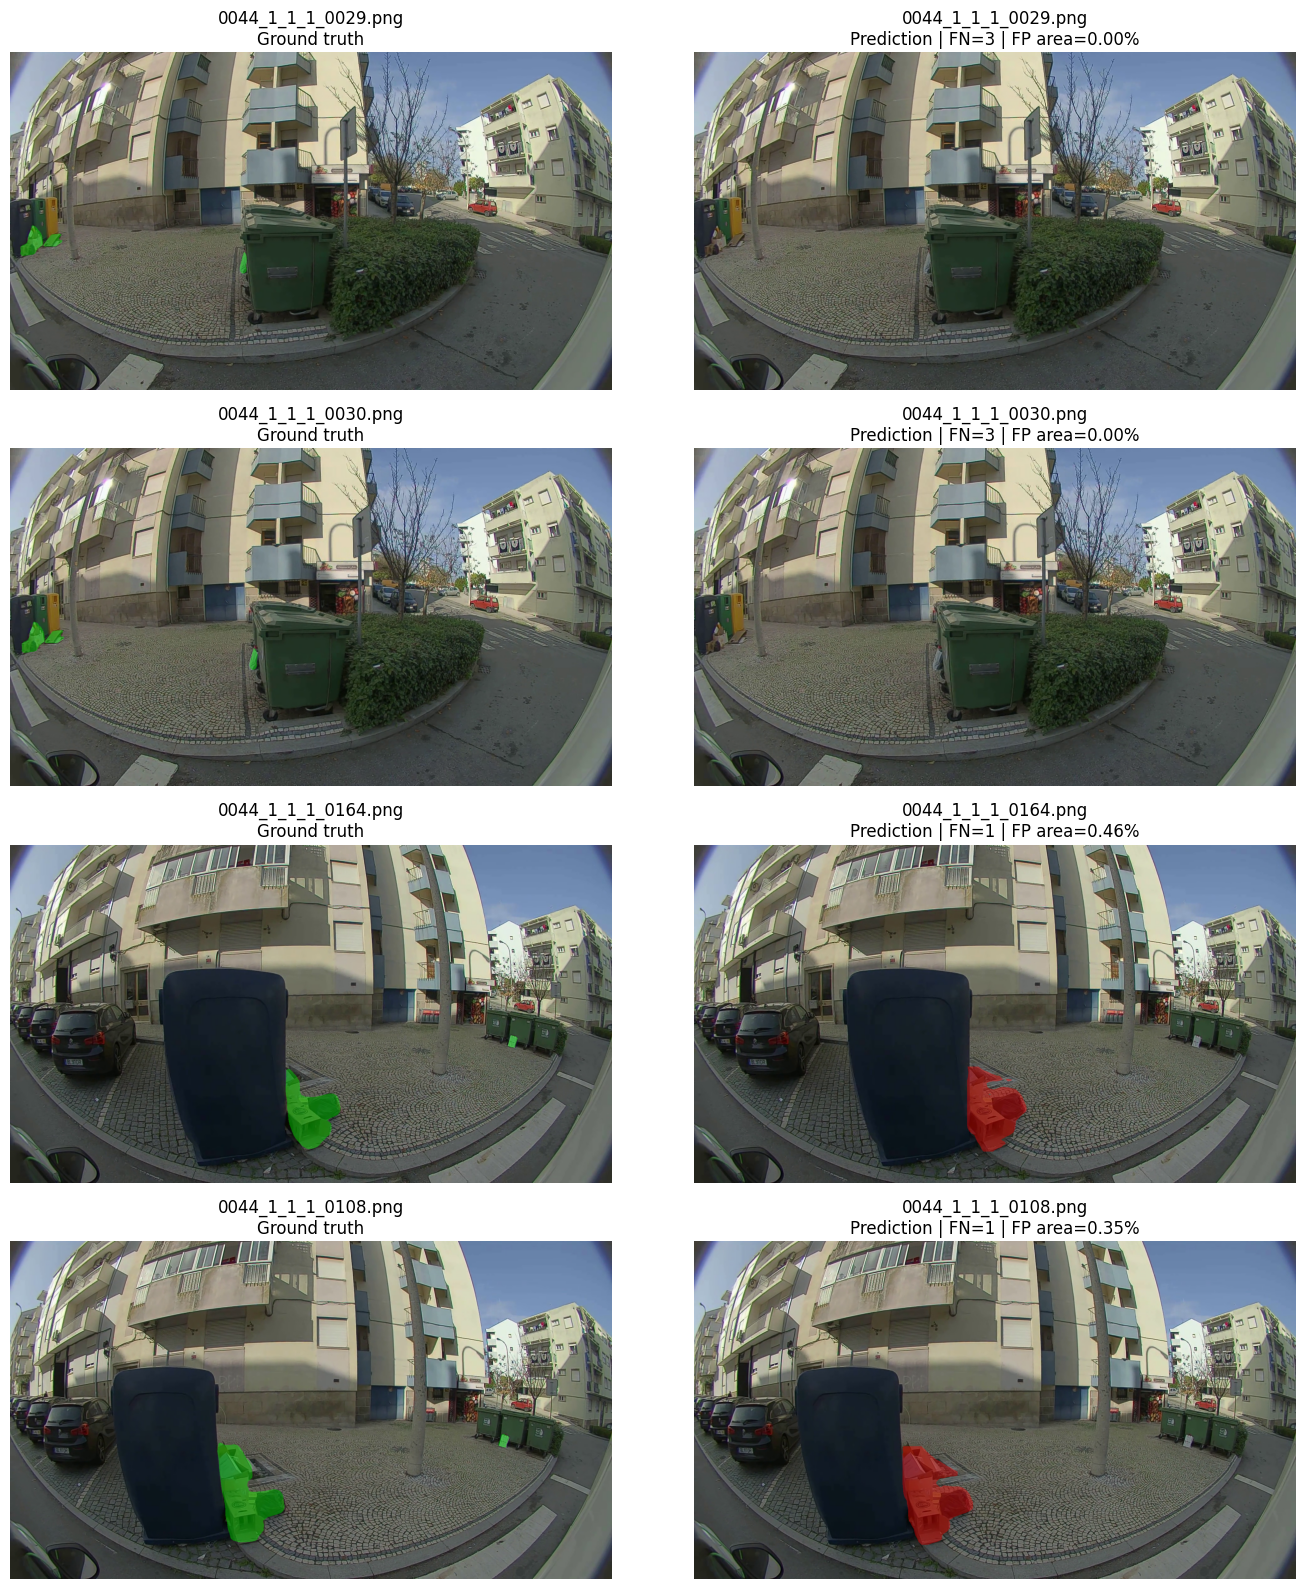

In [14]:
missed_examples = per_image[per_image["FN"] > 0].nlargest(2, "FN")
fp_examples = per_image[per_image["FPPixels"] > 0].nlargest(2, "FPAreaPct")

examples = pd.concat([missed_examples, fp_examples])
examples = examples.loc[~examples.index.duplicated()].head(4)

if examples.empty:
    examples = per_image.head(4)

figure, axes = plt.subplots(
    len(examples), 2,
    figsize=(14, 4 * len(examples)), squeeze=False
)

for row_index, (image_id, row) in enumerate(examples.iterrows()):
    filename = Path(row["Image"]).name
    image = cv2.imread(str(DATA / SPLIT / "images" / filename))
    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    height, width = rgb.shape[:2]

    gt_union = union_mask(
        ground_truth_rles(image_id),
        height, width
    )
    pred_union = union_mask(
        operating_predictions[image_id],
        height, width
    )

    for column, mask, color, title in [
        (0, gt_union, (0, 255, 0), "Ground truth"),
        (
            1, pred_union, (255, 0, 0),
            f"Prediction | FN={int(row['FN'])} "
            f"| FP area={row['FPAreaPct']:.2f}%"
        )
    ]:
        overlay = rgb.copy()
        overlay[mask] = (0.6 * rgb[mask] + 0.4 * np.array(color)).astype(np.uint8)
        axes[row_index, column].imshow(overlay)
        axes[row_index, column].set_title(f"{filename}\n{title}")
        axes[row_index, column].axis("off")

figure.tight_layout()
private_directory = REPORT / "private"
private_directory.mkdir(exist_ok=True)

figure.savefig(
    private_directory / "error_examples.png",
    dpi=140, bbox_inches="tight"
)
plt.show()
plt.close(figure)

In [15]:
summary = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "run_name": RUN_NAME,
    "checkpoint": str(SOURCE_WEIGHTS),
    "checkpoint_sha256": hashlib.sha256(WEIGHTS.read_bytes()).hexdigest(),
    "annotations_sha256": hashlib.sha256(ANNOTATIONS.read_bytes()).hexdigest(),
    "split": SPLIT,
    "images": len(images),
    "positive_images": int((per_image["Objects"] > 0).sum()),
    "negative_images": len(negative_images),
    "metrics": metrics,
    "protocol": {
        "class": "Overflow",
        "yolo_class_id": 0,
        "coco_category_id": CATEGORY_ID,
        "imgsz": IMGSZ,
        "batch": 1,
        "precision": "FP16" if HALF else "FP32",
        "rect": False,
        "retina_masks": True,
        "AP_evaluator": "evaluation.metrics.evaluate_coco",
        "iou_type": "segm",
        "AP_confidence_min": AP_CONF,
        "max_detections_per_image": MAX_DET,
        "supporting_confidence": CONF,
        "supporting_confidence_rule": ">",
        "instance_match_mask_IoU": MATCH_IOU,
        "instance_matching": "Existing COCO matches",
        "IoU_Dice": (
            "Pooled foreground pixels across the split; "
            "empty/empty images add zero pixels"
        ),
        "boundary_IoU": "Mean over matched instance pairs",
        "boundary_width_image_diagonal_ratio": BOUNDARY_RATIO,
        "false_positive_area": (
            "Mean per-image percentage of predicted foreground "
            "outside ground-truth foreground"
        ),
        "missed_overflow_rate": (
            "Unmatched GT instances divided by all GT instances"
        ),
        "latency": (
            "Batch-1 preprocessing, inference, mask postprocessing "
            "and CPU transfer; excludes disk I/O and metrics"
        ),
        "latency_confidence": AP_CONF,
        "latency_images": len(latencies),
        "latency_warmup_iterations": WARMUP
    },
    "environment": {
        "python": platform.python_version(),
        "torch": torch.__version__,
        "ultralytics": ultralytics.__version__,
        "pycocotools": version("pycocotools"),
        "numpy": np.__version__,
        "opencv": cv2.__version__,
        "cuda": torch.version.cuda,
        "gpu": torch.cuda.get_device_name(DEVICE)
    },
}

(REPORT / "metrics.json").write_text(
    json.dumps(summary, indent=2, allow_nan=False), encoding="utf-8"
)
print(REPORT)

/content/drive/MyDrive/WasteScope/reports/segmentation/S0_yolo26n_seg_640/val_best_640_conf0.25
